# Feature Selection

This notebook takes the combined feature table produced by the extraction step and reduces it to a
compact, non-redundant subset. The table holds features from both wearables: chest RespiBAN (`c_`
prefix) and wrist Empatica E4 (`w_` prefix), each in an absolute version and in a version expressed
relative to the subject's own baseline (`_rel`).

With only 15 subjects and a leave-one-subject-out (LOSO) evaluation, the selection cannot be done
once on the whole dataset: anything that learns from the data: imputation, scaling, redundancy filtering, ranking, must be fitted inside each training fold, so the held-out subject never
influences it. The deliverable is therefore a selection *procedure*, applied step by step inside
each fold, not a single fixed table of features.

Two selection strategies are compared: a two-step filter (a correlation filter removes redundant
features, then `SelectKBest` keeps those with the highest mutual information with the class) and
mRMR (minimum redundancy, maximum relevance), which combines the two criteria in a single greedy
step. They are compared at `k = 20`, using a k-nearest-neighbour probe to make the comparison concrete. The actual `k` for each classifier is
tuned jointly with its other hyperparameters in the modelling stage.

## Imports

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import f1_score

from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")

## Loading and cleaning

The combined table is loaded and, as a safeguard, any row missing `subject_id` or `label` is
removed, and both columns are cast back to integers. All remaining columns are kept as
`all_feature_cols` — this full-width table is what actually enters the LOSO pipeline below.

Features missing in more than 30% of a fold's *training* windows are removed inside that fold by
`MissingnessFilter` (defined further down): imputing a mostly-absent column would fabricate data
rather than recover it. Unlike a threshold computed once on the whole dataset, recomputing it per
fold means the held-out subject's data never influences which columns are considered usable — not
even structurally. The cell below also prints a whole-dataset snapshot (`explore_cols`) purely to
illustrate the effect for the exploratory plots that follow; it is not used by the real pipeline and
the exact set of kept columns can vary slightly fold to fold. In both the snapshot and the real
per-fold filtering this is where the wrist cardiac features tend to fall out — the Empatica BVP is
noisy enough that its HRV features are missing on 32-45% of the windows, above the threshold — which
is itself an honest result about the wrist device rather than a defect to patch.

In [3]:
OUT_DIR = "combined_outputs"
features = pd.read_csv(os.path.join(OUT_DIR, "features_all.csv"))
features = features.dropna(subset=["subject_id", "label"]).reset_index(drop=True)
features["subject_id"] = features["subject_id"].astype(int)
features["label"] = features["label"].astype(int)

META = ["label", "label_name", "subject_id"]
all_feature_cols = [c for c in features.columns if c not in META]

def device_of(name):
    return "wrist" if name.startswith("w_") else "chest"

def kind_of(name):
    return "relative" if name.endswith("_rel") else "absolute"

# Whole-dataset missingness snapshot, for the exploratory plots ONLY (below). The real LOSO
# pipeline does NOT use this: the 30%-missingness threshold is recomputed inside every training
# fold by `MissingnessFilter` (defined further down), so the held-out subject never influences
# which columns are considered too sparse to use.
NA_THRESHOLD = 0.30
na_fraction_all = features[all_feature_cols].isna().mean()
dropped_all = na_fraction_all[na_fraction_all > NA_THRESHOLD].index.tolist()
explore_cols = [c for c in all_feature_cols if c not in dropped_all]

print(f"{features.shape[0]} windows, {len(all_feature_cols)} features before cleaning")
print(f"Whole-dataset snapshot (exploratory only): {len(explore_cols)} features would survive "
      f"the >{int(NA_THRESHOLD*100)}% missingness threshold "
      f"({sum(device_of(c)=='chest' for c in explore_cols)} chest + "
      f"{sum(device_of(c)=='wrist' for c in explore_cols)} wrist)")
print(f"Dropped in this snapshot: {len(dropped_all)}")
for c in dropped_all:
    print(f"  {c:22s} missing {na_fraction_all[c]*100:.0f}%")
print("\nNote: the actual LOSO pipeline below recomputes this threshold per fold via "
      "MissingnessFilter, so the exact set of kept columns can vary slightly fold to fold.")

X = features[all_feature_cols].values        # full width; MissingnessFilter narrows this per fold
y = features["label"].values                  # 1 = baseline, 2 = stress, 3 = amusement
y_binary = (y == 2).astype(int)               # stress vs. non-stress
groups = features["subject_id"].values

6123 windows, 128 features before cleaning
Whole-dataset snapshot (exploratory only): 106 features would survive the >30% missingness threshold (78 chest + 28 wrist)
Dropped in this snapshot: 22
  c_SCR_ipi_mean         missing 76%
  w_HR_mean              missing 32%
  w_HR_std               missing 32%
  w_HRV_MeanNN           missing 32%
  w_HRV_SDNN             missing 32%
  w_HRV_RMSSD            missing 32%
  w_HRV_pNN50            missing 32%
  w_HRV_SD1              missing 32%
  w_HRV_SD2              missing 32%
  w_HRV_SampEn           missing 45%
  w_HRV_LFHF             missing 40%
  c_SCR_ipi_mean_rel     missing 88%
  w_HR_mean_rel          missing 32%
  w_HR_std_rel           missing 32%
  w_HRV_MeanNN_rel       missing 32%
  w_HRV_SDNN_rel         missing 32%
  w_HRV_RMSSD_rel        missing 32%
  w_HRV_pNN50_rel        missing 32%
  w_HRV_SD1_rel          missing 32%
  w_HRV_SD2_rel          missing 32%
  w_HRV_SampEn_rel       missing 45%
  w_HRV_LFHF_rel         mis

## Exploratory analysis

The plots below are computed on the whole dataset and serve only to understand the data; they are
not the selection that enters the results, which is fitted inside the folds further down. Missing
values are median-filled here purely for exploration.


In [4]:
print("Class balance:")
print(features["label_name"].value_counts(), "\n")

n_chest = sum(device_of(c) == "chest" for c in explore_cols)
n_wrist = sum(device_of(c) == "wrist" for c in explore_cols)
n_abs = sum(kind_of(c) == "absolute" for c in explore_cols)
n_rel = sum(kind_of(c) == "relative" for c in explore_cols)
print(f"Kept features by device: chest {n_chest}, wrist {n_wrist}")
print(f"Kept features by type:   absolute {n_abs}, relative {n_rel}")

X_explore = features[explore_cols].fillna(features[explore_cols].median()).values

Class balance:
label_name
baseline     3354
stress       1826
amusement     943
Name: count, dtype: int64 

Kept features by device: chest 78, wrist 28
Kept features by type:   absolute 53, relative 53


### Class balance and feature distributions by class 

This single figure is the report's Figure 1 for Section 2.1 (Exploratory Data Analysis): a
class-balance panel plus box plots of four representative features split by class. Like the
correlation heatmap and mutual-information ranking below, it is computed on the whole dataset for
illustration only and does not feed the LOSO selection pipeline — it shows that the signal
separates classes *before* any selection or classification happens.


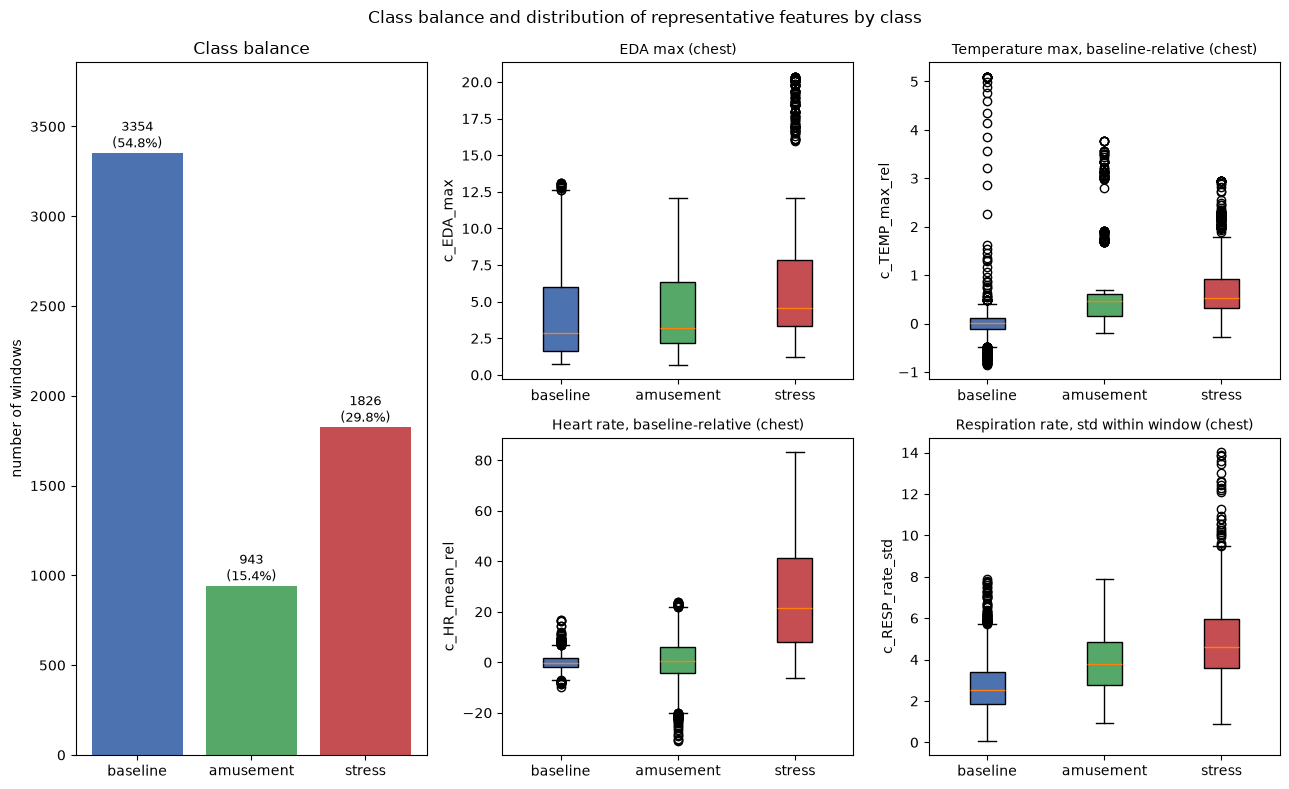

In [5]:
CLASS_ORDER = ["baseline", "amusement", "stress"]
CLASS_COLORS = {"baseline": "#4C72B0", "amusement": "#55A868", "stress": "#C44E52"}
DIST_FEATURES = ["c_EDA_max", "c_TEMP_max_rel", "c_HR_mean_rel", "c_RESP_rate_std"]
DIST_TITLES = {
    "c_EDA_max": "EDA max (chest)",
    "c_TEMP_max_rel": "Temperature max, baseline-relative (chest)",
    "c_HR_mean_rel": "Heart rate, baseline-relative (chest)",
    "c_RESP_rate_std": "Respiration rate, std within window (chest)",
}

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1])

# Left panel (spans both rows): class balance.
ax_bal = fig.add_subplot(gs[:, 0])
class_counts = features["label_name"].value_counts().reindex(CLASS_ORDER)
ax_bal.bar(class_counts.index, class_counts.values,
           color=[CLASS_COLORS[c] for c in class_counts.index])
for i, v in enumerate(class_counts.values):
    ax_bal.text(i, v + 30, f"{v}\n({v / class_counts.sum() * 100:.1f}%)", ha="center", fontsize=9)
ax_bal.set_title("Class balance")
ax_bal.set_ylabel("number of windows")
ax_bal.margins(y=0.15)

# Right 2x2 grid: distributions by class.
grid_positions = [(0, 1), (0, 2), (1, 1), (1, 2)]
for (row, col), feat in zip(grid_positions, DIST_FEATURES):
    ax = fig.add_subplot(gs[row, col])
    data = [features.loc[features["label_name"] == cls, feat].dropna() for cls in CLASS_ORDER]
    bp = ax.boxplot(data, tick_labels=CLASS_ORDER, patch_artist=True)
    for patch, cls in zip(bp["boxes"], CLASS_ORDER):
        patch.set_facecolor(CLASS_COLORS[cls])
    ax.set_title(DIST_TITLES[feat], fontsize=10)
    ax.set_ylabel(feat)

fig.suptitle("Class balance and distribution of representative features by class")
plt.tight_layout()
plt.show()

### Correlation structure

Features are ordered by device and then by absolute/relative, so the heatmap shows block
structure: small blocks on the main diagonal group related descriptors of the same signal (e.g.
several EDA statistics next to each other), while a fainter band offset from the main diagonal —
between the absolute and the relative sub-block of each device — reflects the expected redundancy
between a feature and its own baseline-relative version.

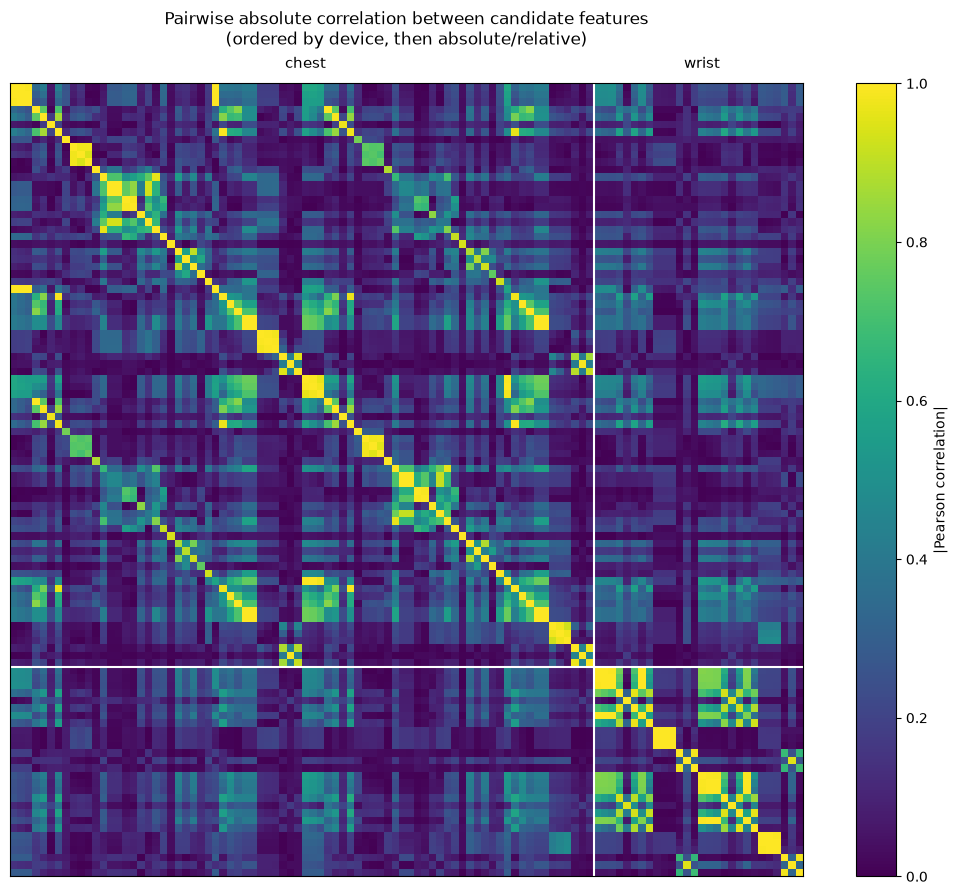

90 feature pairs with |correlation| > 0.9 (redundancy candidates)
  c_SCR_count            ~ c_SCR_rate              r = 1.00
  c_SCR_count_rel        ~ c_SCR_rate_rel          r = 1.00
  c_SCL_mean             ~ c_EDA_mean              r = 1.00
  w_EDA_mean             ~ w_SCL_mean              r = 1.00
  c_SCL_mean_rel         ~ c_EDA_mean_rel          r = 1.00
  w_EDA_mean_rel         ~ w_SCL_mean_rel          r = 1.00
  c_HRV_RMSSD            ~ c_HRV_SD1               r = 1.00
  c_HRV_RMSSD_rel        ~ c_HRV_SD1_rel           r = 1.00
  c_EDA_psd_power        ~ c_EDA_psd_power_rel     r = 1.00
  c_SCR_amp_std          ~ c_SCR_amp_std_rel       r = 1.00
  w_TEMP_mean            ~ w_TEMP_min              r = 1.00
  w_TEMP_mean            ~ w_TEMP_max              r = 1.00
  w_TEMP_mean_rel        ~ w_TEMP_min_rel          r = 1.00
  w_TEMP_mean_rel        ~ w_TEMP_max_rel          r = 1.00
  w_TEMP_min             ~ w_TEMP_max              r = 1.00


In [6]:
ordered = sorted(explore_cols, key=lambda c: (device_of(c) == "wrist", kind_of(c) == "relative", c))
Xo = features[ordered].fillna(features[ordered].median()).values
corr = np.corrcoef(Xo, rowvar=False)

n_chest_ord = sum(device_of(c) == "chest" for c in ordered)
n_total_ord = len(ordered)
split = n_chest_ord - 0.5

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(np.abs(np.nan_to_num(corr)), cmap="viridis", vmin=0, vmax=1)
ax.axhline(split, color="white", linewidth=1.5)
ax.axvline(split, color="white", linewidth=1.5)
# Blended transform: x in data units, y as a fraction of the axes height (0=bottom, 1=top), so the
# labels sit just above the heatmap regardless of how many rows/columns it has.
label_transform = ax.get_xaxis_transform()
ax.text(n_chest_ord / 2, 1.015, "chest", ha="center", va="bottom", fontsize=11,
        transform=label_transform)
ax.text(n_chest_ord + (n_total_ord - n_chest_ord) / 2, 1.015, "wrist", ha="center", va="bottom",
        fontsize=11, transform=label_transform)
ax.set_title("Pairwise absolute correlation between candidate features\n(ordered by device, then absolute/relative)",
              pad=28)
ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, label="|Pearson correlation|")
plt.tight_layout(); plt.show()

# Redundancy candidates on the whole set (exploratory only).
c_abs = np.abs(np.nan_to_num(np.corrcoef(X_explore, rowvar=False)))
pairs = [(explore_cols[i], explore_cols[j], c_abs[i, j])
         for i in range(len(explore_cols)) for j in range(i + 1, len(explore_cols))
         if c_abs[i, j] > 0.9]
print(f"{len(pairs)} feature pairs with |correlation| > 0.9 (redundancy candidates)")
for a, b, r in sorted(pairs, key=lambda t: -t[2])[:15]:
    print(f"  {a:22s} ~ {b:22s}  r = {r:.2f}")

### Mutual information with the class

Each feature's mutual information with the three-class label is estimated with scikit-learn's
nearest-neighbour estimator (Ross, 2014), which works on continuous features without discretisation.
The ranking is annotated by device so it is visible whether chest or wrist features carry more
signal.


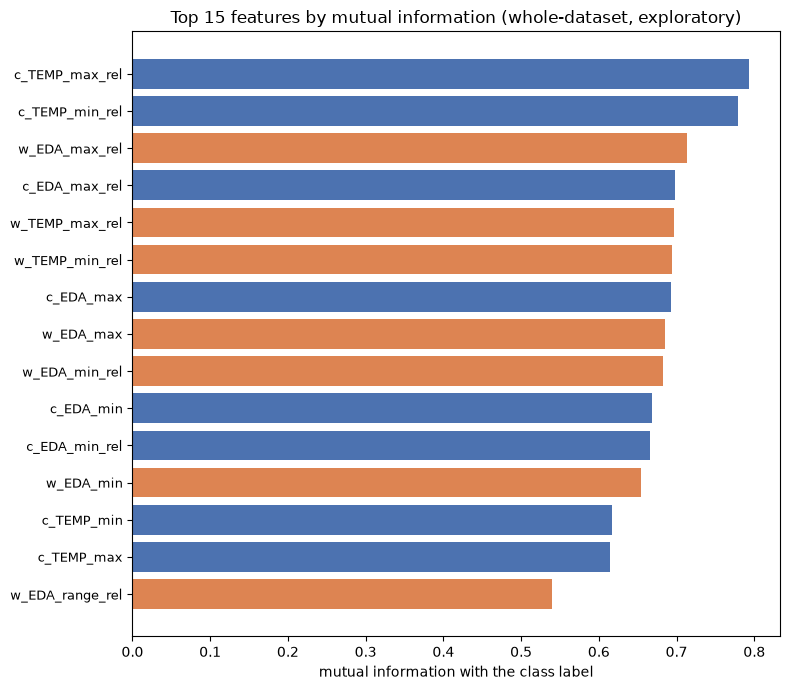

Mean mutual information  chest: 0.287   wrist: 0.367

Top 15 features:
c_TEMP_max_rel     0.793388
c_TEMP_min_rel     0.779652
w_EDA_max_rel      0.713137
c_EDA_max_rel      0.698530
w_TEMP_max_rel     0.696583
w_TEMP_min_rel     0.694528
c_EDA_max          0.692898
w_EDA_max          0.684684
w_EDA_min_rel      0.682005
c_EDA_min          0.667935
c_EDA_min_rel      0.665450
w_EDA_min          0.654663
c_TEMP_min         0.617288
c_TEMP_max         0.614548
w_EDA_range_rel    0.539159
dtype: float64


In [7]:
mi = mutual_info_classif(StandardScaler().fit_transform(X_explore), y, random_state=0)
ranking = pd.Series(mi, index=explore_cols).sort_values(ascending=False)

N_TOP = 15   # matches K_REF used later in this notebook and Section 3.2 of the report
top = ranking.head(N_TOP).iloc[::-1]
colors = ["#4C72B0" if device_of(c) == "chest" else "#DD8452" for c in top.index]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(range(len(top)), top.values, color=colors)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index, fontsize=9)
ax.set_title(f"Top {N_TOP} features by mutual information (whole-dataset, exploratory)")
ax.set_xlabel("mutual information with the class label")
plt.tight_layout(); plt.show()

chest_mi = ranking[[c for c in explore_cols if device_of(c) == "chest"]].mean()
wrist_mi = ranking[[c for c in explore_cols if device_of(c) == "wrist"]].mean()
print(f"Mean mutual information  chest: {chest_mi:.3f}   wrist: {wrist_mi:.3f}")
print(f"\nTop {N_TOP} features:")
print(ranking.head(N_TOP))

## Selection methods

Three transformers, fitted inside each LOSO fold like everything else in this notebook.
`MissingnessFilter` recomputes the >30% missingness threshold on the training fold only.
`CorrelationFilter` drops redundant features (|r| > threshold), visiting candidates from most to
least informative by mutual information, so of two correlated features the more informative one is
always kept. `MRMRSelector` grows the set greedily by relevance-minus-redundancy, adding one
feature at a time.

In [ ]:
class MissingnessFilter(BaseEstimator, TransformerMixin):
    """Drop columns missing in more than `threshold` of the fold's training rows. Fitted on the
    training fold only, so the missingness threshold never sees the held-out subject."""
    def __init__(self, threshold=0.30):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, float)
        na_fraction = np.isnan(X).mean(axis=0)
        self.keep_ = np.where(na_fraction <= self.threshold)[0].tolist()
        return self

    def transform(self, X):
        return np.asarray(X, float)[:, self.keep_]


class CorrelationFilter(BaseEstimator, TransformerMixin):
    """Drop features whose absolute correlation with an already-kept feature exceeds `threshold`.
    Candidates are visited in decreasing order of mutual information with the class, so of two
    correlated features the more informative one is always kept rather than whichever happens to
    come first in column order."""
    def __init__(self, threshold=0.9):
        self.threshold = threshold

    def fit(self, X, y):
        X = np.asarray(X, float)
        c = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        n = c.shape[0]
        relevance = mutual_info_classif(X, y, random_state=0)
        order = np.argsort(relevance)[::-1]   # column indices, most informative first
        drop = set()
        for pos, i in enumerate(order):
            if i in drop:
                continue
            for j in order[pos + 1:]:
                if j not in drop and c[i, j] > self.threshold:
                    drop.add(int(j))
        self.keep_ = [i for i in range(n) if i not in drop]
        return self

    def transform(self, X):
        return np.asarray(X, float)[:, self.keep_]


class MRMRSelector(BaseEstimator, TransformerMixin):
    """Greedy mRMR: maximise MI(feature, class) minus mean |correlation| with the already-selected
    features. Produces an ordered list `selected_`, whose first k entries are the size-k selection."""
    def __init__(self, k=15):
        self.k = k

    def fit(self, X, y):
        X = np.asarray(X, float)
        n = X.shape[1]
        k = min(self.k, n)
        relevance = mutual_info_classif(X, y, random_state=0)
        redundancy = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        selected = [int(np.argmax(relevance))]
        candidates = [i for i in range(n) if i != selected[0]]
        while len(selected) < k:
            scores = [relevance[f] - redundancy[f, selected].mean() for f in candidates]
            best = candidates[int(np.argmax(scores))]
            selected.append(best)
            candidates.remove(best)
        self.selected_ = selected
        return self

    def transform(self, X):
        return np.asarray(X, float)[:, self.selected_]

## Comparing the two selectors

The two selection procedures are compared directly at a representative feature-set size, `k = 20`. Because the same LOSO folds are used for both selectors, the per-fold F1 scores are
paired, so a Wilcoxon signed-rank test says whether any difference is systematic or just
fold-to-fold noise. This is the same reasoning applied to the absolute-versus-relative and
chest-versus-wrist questions elsewhere in the project.

In [9]:
K_REF = 20    # representative size for the comparison — the minimum of the real
              # K_GRID_COMBINED = [20, 40, 'all'] used for the actual combined classifiers,
              # not chest's k = 15
logo = LeaveOneGroupOut()

def loso_f1_filter(target, k):
    scores = []
    for tr, te in logo.split(X, target, groups):
        mf = MissingnessFilter(threshold=NA_THRESHOLD).fit(X[tr])
        Xtr_m, Xte_m = mf.transform(X[tr]), mf.transform(X[te])
        imp = SimpleImputer(strategy="median").fit(Xtr_m)
        sc = StandardScaler().fit(imp.transform(Xtr_m))
        Xtr, Xte = sc.transform(imp.transform(Xtr_m)), sc.transform(imp.transform(Xte_m))
        cf = CorrelationFilter(threshold=0.9).fit(Xtr, target[tr])
        skb = SelectKBest(mutual_info_classif, k=min(k, len(cf.keep_))).fit(cf.transform(Xtr), target[tr])
        sel = skb.get_support()
        clf = KNeighborsClassifier(n_neighbors=5).fit(cf.transform(Xtr)[:, sel], target[tr])
        scores.append(f1_score(target[te], clf.predict(cf.transform(Xte)[:, sel]), average="macro"))
    return np.array(scores)

def loso_f1_mrmr(target, k):
    scores = []
    for tr, te in logo.split(X, target, groups):
        mf = MissingnessFilter(threshold=NA_THRESHOLD).fit(X[tr])
        Xtr_m, Xte_m = mf.transform(X[tr]), mf.transform(X[te])
        imp = SimpleImputer(strategy="median").fit(Xtr_m)
        sc = StandardScaler().fit(imp.transform(Xtr_m))
        Xtr, Xte = sc.transform(imp.transform(Xtr_m)), sc.transform(imp.transform(Xte_m))
        sel = MRMRSelector(k=k).fit(Xtr, target[tr]).selected_
        clf = KNeighborsClassifier(n_neighbors=5).fit(Xtr[:, sel], target[tr])
        scores.append(f1_score(target[te], clf.predict(Xte[:, sel]), average="macro"))
    return np.array(scores)

for task, target in [("three-class", y), ("stress vs. rest", y_binary)]:
    a = loso_f1_filter(target, K_REF)
    b = loso_f1_mrmr(target, K_REF)
    stat, p = wilcoxon(a, b)
    print(f"{task:16s} (k={K_REF}):  filter {a.mean():.3f} +/- {a.std():.3f}   "
          f"mRMR {b.mean():.3f} +/- {b.std():.3f}   Wilcoxon p = {p:.3f}")

three-class      (k=20):  filter 0.642 +/- 0.170   mRMR 0.617 +/- 0.173   Wilcoxon p = 0.221
stress vs. rest  (k=20):  filter 0.831 +/- 0.202   mRMR 0.793 +/- 0.222   Wilcoxon p = 0.182
